SESSÃO 05 — ANÁLISE EXPLORATÓRIA DO CONJUNTO SELECIONADO

Trabalho: C1 — Classificação supervisionada de eventos indesejados em poços de petróleo.

Dataset: Petrobras 3W 2.0.0.

Objetivo: caracterizar os dados reais do particionamento V3 e investigar suas propriedades estatísticas antes da preparação das janelas temporais e do treinamento dos modelos.

Protocolo: V3 candidata, com divisão agrupada por poço.

In [1]:

# SESSAO 05 - TAREFA 01
# Importacao e conferencia do protocolo V3

import io
import zipfile
import pandas as pd
from google.colab import files

# 1. Enviar o pacote ZIP
print("Selecione o arquivo da V3:")
arquivos_enviados = files.upload()

nome_zip = next(
    nome for nome in arquivos_enviados
    if nome.lower().endswith(".zip")
)

# 2. Ler os manifestos diretamente do ZIP
with zipfile.ZipFile(
    io.BytesIO(arquivos_enviados[nome_zip])
) as pacote:

    pocos_v3 = pd.read_csv(
        pacote.open("01_Pocos_V3.csv")
    )

    instancias_v3 = pd.read_csv(
        pacote.open("02_Instancias_Reais_V3.csv")
    )

# 3. Resumir as particoes
resumo_v3 = (
    instancias_v3
    .groupby("Conjunto")
    .agg(
        Pocos=("Poco", "nunique"),
        Instancias=("Arquivo", "count")
    )
    .reindex(["Treino", "Validacao", "Teste"])
)

print("\nRESUMO DO PROTOCOLO V3:")
display(resumo_v3)

# 4. Conferencias de integridade
assert len(instancias_v3) == 1119
assert instancias_v3["Poco"].nunique() == 40

assert (
    instancias_v3.groupby("Poco")["Conjunto"]
    .nunique() == 1
).all()

# 5. Separar o treinamento para analise
dados_treino_v3 = instancias_v3[
    instancias_v3["Conjunto"] == "Treino"
].copy()

print("\nInstancias de treinamento:",
      len(dados_treino_v3))

print("\nTAREFA 01 CONCLUIDA")


Selecione o arquivo da V3:


Saving Bloco_C_Protocolo_V3_CANDIDATO.zip to Bloco_C_Protocolo_V3_CANDIDATO.zip

RESUMO DO PROTOCOLO V3:


,Pocos,Instancias
Conjunto,,
Treino,28,528
Validacao,6,183
Teste,6,408



Instancias de treinamento: 528

TAREFA 01 CONCLUIDA


DISTRIBUICAO DAS CATEGORIAS NA V3:


Conjunto,Treino,Validacao,Teste,Total
Categoria,,,,
0,268,107,219,594
1,1,0,3,4
2,18,3,1,22
3,31,0,1,32
4,143,38,162,343
5,6,1,4,11
6,3,0,3,6
7,6,27,3,36
8,10,0,4,14



FREQUENCIAS NO TREINAMENTO:


,Instancias,Percentual (%)
Categoria,,
0,268,50.76
1,1,0.19
2,18,3.41
3,31,5.87
4,143,27.08
5,6,1.14
6,3,0.57
7,6,1.14
8,10,1.89


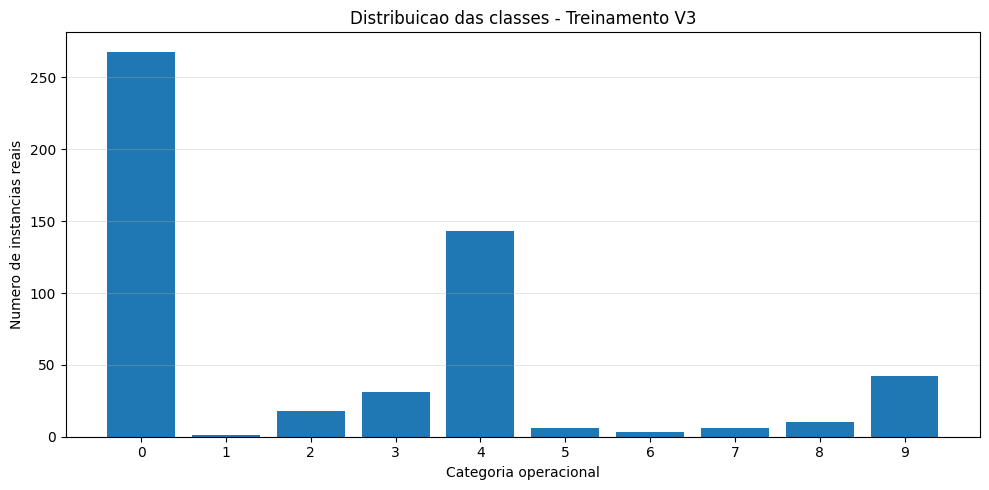

Classes ausentes em Treino: []
Classes ausentes em Validacao: [1, 3, 6, 8]
Classes ausentes em Teste: []


In [3]:

# ====================================================
# SESSAO 05 - TAREFA 02
# Distribuicao das categorias no protocolo V3
# ====================================================

import pandas as pd
import matplotlib.pyplot as plt

# 1. Contagem de instancias por categoria e conjunto
distribuicao = pd.crosstab(
    instancias_v3["Categoria"],
    instancias_v3["Conjunto"]
)

# Garantir a visualizacao das classes 0 a 9
distribuicao = distribuicao.reindex(
    index=range(10),
    columns=["Treino", "Validacao", "Teste"],
    fill_value=0
)

# 2. Acrescentar o total por categoria
distribuicao["Total"] = distribuicao.sum(axis=1)

print("DISTRIBUICAO DAS CATEGORIAS NA V3:")
display(distribuicao)

# 3. Calcular frequencias no treinamento
frequencias_treino = pd.DataFrame({
    "Instancias": distribuicao["Treino"]
})

frequencias_treino["Percentual (%)"] = (
    frequencias_treino["Instancias"]
    / len(dados_treino_v3) * 100
).round(2)

print("\nFREQUENCIAS NO TREINAMENTO:")
display(frequencias_treino)

# 4. Grafico da distribuicao no treinamento
plt.figure(figsize=(10, 5))

plt.bar(
    frequencias_treino.index.astype(str),
    frequencias_treino["Instancias"]
)

plt.title(
    "Distribuicao das classes - Treinamento V3"
)
plt.xlabel("Categoria operacional")
plt.ylabel("Numero de instancias reais")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Identificar classes ausentes por conjunto
for conjunto in ["Treino", "Validacao", "Teste"]:
    ausentes = distribuicao.index[
        distribuicao[conjunto] == 0
    ].tolist()

    print(
        f"Classes ausentes em {conjunto}: {ausentes}"
    )


In [4]:

# ====================================================
# SESSAO 05 - TAREFA 03 - ATIVIDADE 01
# Inspecao inicial das variaveis de uma instancia real
# ====================================================

import io
import requests
import pandas as pd

# 1. Selecionar uma instancia do treinamento V3
nome_arquivo = "WELL-00002_20131104004101.parquet"

registro = instancias_v3[
    (instancias_v3["Arquivo"] == nome_arquivo) &
    (instancias_v3["Conjunto"] == "Treino")
]

assert len(registro) == 1, (
    "Arquivo nao encontrado no treinamento V3."
)

categoria = int(registro.iloc[0]["Categoria"])

# 2. Obter o arquivo Parquet oficial
url = (
    f"https://raw.githubusercontent.com/petrobras/3W/"
    f"main/dataset/{categoria}/{nome_arquivo}"
)

resposta = requests.get(url, timeout=60)
resposta.raise_for_status()

assert resposta.content[:4] == b"PAR1", (
    "O arquivo recebido nao e um Parquet valido."
)

df_exemplo = pd.read_parquet(
    io.BytesIO(resposta.content)
)

# 3. Conferir a estrutura
print("ARQUIVO:", nome_arquivo)
print("CATEGORIA:", categoria)
print("DIMENSOES:", df_exemplo.shape)

print("\nCOLUNAS DISPONIVEIS:")
print(df_exemplo.columns.tolist())

print("\nTIPOS DE DADOS:")
display(df_exemplo.dtypes.to_frame("Tipo"))

# 4. Inspecionar variaveis numericas
sensores = [
    coluna for coluna in df_exemplo.columns
    if coluna.lower() not in ["class", "label"]
    and pd.api.types.is_numeric_dtype(df_exemplo[coluna])
]

diagnostico = pd.DataFrame({
    "Valores validos (%)": (
        df_exemplo[sensores].notna().mean() * 100
    ).round(2),
    "Valores distintos": (
        df_exemplo[sensores].nunique(dropna=True)
    )
})

diagnostico["Constante"] = (
    diagnostico["Valores distintos"] == 1
)

print("\nDIAGNOSTICO INICIAL DAS VARIAVEIS:")
display(diagnostico)


ARQUIVO: WELL-00002_20131104004101.parquet
CATEGORIA: 2
DIMENSOES: (12721, 29)

COLUNAS DISPONIVEIS:
['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL', 'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL', 'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-CKP', 'P-MON-SDV-P', 'P-PDG', 'PT-P', 'P-TPT', 'QBS', 'QGL', 'T-JUS-CKP', 'T-MON-CKP', 'T-PDG', 'T-TPT', 'class', 'state']

TIPOS DE DADOS:


,Tipo
ABER-CKGL,float64
ABER-CKP,float64
ESTADO-DHSV,float64
ESTADO-M1,float64
ESTADO-M2,float64
ESTADO-PXO,float64
ESTADO-SDV-GL,float64
ESTADO-SDV-P,float64
ESTADO-W1,float64
ESTADO-W2,float64



DIAGNOSTICO INICIAL DAS VARIAVEIS:


,Valores validos (%),Valores distintos,Constante
ABER-CKGL,0.0,0,False
ABER-CKP,0.0,0,False
ESTADO-DHSV,0.0,0,False
ESTADO-M1,0.0,0,False
ESTADO-M2,0.0,0,False
ESTADO-PXO,0.0,0,False
ESTADO-SDV-GL,0.0,0,False
ESTADO-SDV-P,0.0,0,False
ESTADO-W1,0.0,0,False
ESTADO-W2,0.0,0,False


In [5]:

# SESSAO 05 - TAREFA 03 - ATIVIDADE 02
# Auditoria dos sensores nos 528 arquivos do treinamento

import io
import requests
import pandas as pd
from tqdm.auto import tqdm

sensores = [
    c for c in df_exemplo.columns
    if c not in ["class", "state"]
]

resultados = []
falhas = []

with requests.Session() as sessao:
    for _, item in tqdm(
        dados_treino_v3.iterrows(),
        total=len(dados_treino_v3)
    ):
        arquivo = item["Arquivo"]
        categoria = int(item["Categoria"])

        url = (
            "https://raw.githubusercontent.com/petrobras/3W/"
            f"main/dataset/{categoria}/{arquivo}"
        )

        try:
            resposta = sessao.get(url, timeout=60)
            resposta.raise_for_status()

            df = pd.read_parquet(
                io.BytesIO(resposta.content)
            )

            for sensor in sensores:
                if sensor in df.columns:
                    serie = df[sensor]
                    validos = int(serie.notna().sum())
                    distintos = int(
                        serie.nunique(dropna=True)
                    )
                else:
                    validos = 0
                    distintos = 0

                resultados.append({
                    "Arquivo": arquivo,
                    "Sensor": sensor,
                    "Linhas": len(df),
                    "Validos": validos,
                    "Tem_dados": int(validos > 0),
                    "Variavel": int(distintos > 1),
                    "Constante": int(
                        validos > 0 and distintos == 1
                    )
                })

        except Exception as erro:
            falhas.append({
                "Arquivo": arquivo,
                "Erro": str(erro)
            })

# Resumo por sensor
auditoria = pd.DataFrame(resultados)

if auditoria.empty:
    raise RuntimeError("Nenhum arquivo foi analisado.")

resumo_sensores = auditoria.groupby("Sensor").agg(
    Arquivos_com_dados=("Tem_dados", "sum"),
    Arquivos_variaveis=("Variavel", "sum"),
    Arquivos_constantes=("Constante", "sum"),
    Linhas=("Linhas", "sum"),
    Medicoes_validas=("Validos", "sum")
)

total_analisados = auditoria["Arquivo"].nunique()

resumo_sensores["Disponibilidade_arquivos_%"] = (
    100 * resumo_sensores["Arquivos_com_dados"]
    / total_analisados
).round(2)

resumo_sensores["Medicoes_validas_%"] = (
    100 * resumo_sensores["Medicoes_validas"]
    / resumo_sensores["Linhas"]
).round(2)

resumo_sensores = resumo_sensores.sort_values(
    "Disponibilidade_arquivos_%",
    ascending=False
)

print("ARQUIVOS ANALISADOS:", total_analisados)
print("FALHAS DE LEITURA:", len(falhas))

print("\nDISPONIBILIDADE DOS SENSORES:")
display(resumo_sensores)

if falhas:
    print("\nARQUIVOS COM ERRO:")
    display(pd.DataFrame(falhas).head(20))
    print("ATENCAO: auditoria parcial.")

resumo_sensores.to_csv(
    "05_Resumo_Disponibilidade_Sensores_V3.csv"
)
auditoria.to_csv(
    "05_Auditoria_Sensores_V3.csv",
    index=False
)


  0%|          | 0/528 [00:00<?, ?it/s]

ARQUIVOS ANALISADOS: 522
FALHAS DE LEITURA: 6

DISPONIBILIDADE DOS SENSORES:


,Arquivos_com_dados,Arquivos_variaveis,Arquivos_constantes,Linhas,Medicoes_validas,Disponibilidade_arquivos_%,Medicoes_validas_%
Sensor,,,,,,,
P-TPT,458,432,26,16025272,11947847,87.74,74.56
P-PDG,445,112,333,16025272,11671601,85.25,72.83
T-TPT,444,434,10,16025272,11742837,85.06,73.28
P-ANULAR,425,424,1,16025272,11196102,81.42,69.87
P-JUS-CKGL,185,185,0,16025272,9532706,35.44,59.49
P-MON-CKP,131,131,0,16025272,9062013,25.10,56.55
QGL,128,106,22,16025272,7513314,24.52,46.88
T-PDG,127,108,19,16025272,7111838,24.33,44.38
ESTADO-SDV-P,115,5,110,16025272,8180806,22.03,51.05



ARQUIVOS COM ERRO:


,Arquivo,Erro
0,WELL-00002_20140126090141.parquet,503 Server Error: Service Unavailable for url:...
1,WELL-00002_20140126180030.parquet,503 Server Error: Service Unavailable for url:...
2,WELL-00002_20170209110022.parquet,503 Server Error: Service Unavailable for url:...
3,WELL-00002_20170210170033.parquet,503 Server Error: Service Unavailable for url:...
4,WELL-00002_20170212090203.parquet,503 Server Error: Service Unavailable for url:...
5,WELL-00002_20170213200214.parquet,503 Server Error: Service Unavailable for url:...


ATENCAO: auditoria parcial.


In [6]:

# SESSAO 05 - TAREFA 03
# Recuperacao dos arquivos com falha

import io
import time
import requests
import pandas as pd

# Identificar arquivos ainda nao analisados
arquivos_ok = set(auditoria["Arquivo"].unique())

pendentes = dados_treino_v3[
    ~dados_treino_v3["Arquivo"].isin(arquivos_ok)
]

print("ARQUIVOS PENDENTES:", len(pendentes))

novos_resultados = []
falhas_restantes = []

for _, item in pendentes.iterrows():

    arquivo = item["Arquivo"]
    categoria = int(item["Categoria"])

    url = (
        "https://raw.githubusercontent.com/petrobras/3W/"
        f"main/dataset/{categoria}/{arquivo}"
    )

    df = None

    # Ate tres tentativas por arquivo
    for tentativa in range(3):
        try:
            resposta = requests.get(url, timeout=60)
            resposta.raise_for_status()

            df = pd.read_parquet(
                io.BytesIO(resposta.content)
            )
            break

        except Exception as erro:
            ultimo_erro = str(erro)

            if tentativa < 2:
                time.sleep(2 ** (tentativa + 1))

    if df is None:
        falhas_restantes.append({
            "Arquivo": arquivo,
            "Erro": ultimo_erro
        })
        continue

    for sensor in sensores:

        if sensor in df.columns:
            serie = df[sensor]
            validos = int(serie.notna().sum())
            distintos = int(serie.nunique(dropna=True))
        else:
            validos = 0
            distintos = 0

        novos_resultados.append({
            "Arquivo": arquivo,
            "Sensor": sensor,
            "Linhas": len(df),
            "Validos": validos,
            "Tem_dados": int(validos > 0),
            "Variavel": int(distintos > 1),
            "Constante": int(
                validos > 0 and distintos == 1
            )
        })

# Incorporar apenas os arquivos recuperados
if novos_resultados:
    auditoria = pd.concat(
        [auditoria, pd.DataFrame(novos_resultados)],
        ignore_index=True
    )

# Recalcular o resumo
total_analisados = auditoria["Arquivo"].nunique()

resumo_sensores = auditoria.groupby("Sensor").agg(
    Arquivos_com_dados=("Tem_dados", "sum"),
    Arquivos_variaveis=("Variavel", "sum"),
    Arquivos_constantes=("Constante", "sum"),
    Linhas=("Linhas", "sum"),
    Medicoes_validas=("Validos", "sum")
)

resumo_sensores["Disponibilidade_arquivos_%"] = (
    100 * resumo_sensores["Arquivos_com_dados"]
    / total_analisados
).round(2)

resumo_sensores["Medicoes_validas_%"] = (
    100 * resumo_sensores["Medicoes_validas"]
    / resumo_sensores["Linhas"]
).round(2)

resumo_sensores = resumo_sensores.sort_values(
    "Disponibilidade_arquivos_%",
    ascending=False
)

print("\nARQUIVOS ANALISADOS:", total_analisados)
print("ARQUIVOS PENDENTES:", len(falhas_restantes))

print("\nRESUMO ATUALIZADO:")
display(resumo_sensores)

if falhas_restantes:
    print("\nFALHAS REMANESCENTES:")
    display(pd.DataFrame(falhas_restantes))

# Salvar os resultados atualizados
auditoria.to_csv(
    "05_Auditoria_Sensores_V3.csv",
    index=False
)

resumo_sensores.to_csv(
    "05_Resumo_Disponibilidade_Sensores_V3.csv"
)


ARQUIVOS PENDENTES: 6

ARQUIVOS ANALISADOS: 528
ARQUIVOS PENDENTES: 0

RESUMO ATUALIZADO:


,Arquivos_com_dados,Arquivos_variaveis,Arquivos_constantes,Linhas,Medicoes_validas,Disponibilidade_arquivos_%,Medicoes_validas_%
Sensor,,,,,,,
P-TPT,464,438,26,16140035,12062610,87.88,74.74
P-PDG,451,112,339,16140035,11786364,85.42,73.03
T-TPT,450,440,10,16140035,11857600,85.23,73.47
P-ANULAR,431,430,1,16140035,11310865,81.63,70.08
P-JUS-CKGL,185,185,0,16140035,9532706,35.04,59.06
P-MON-CKP,131,131,0,16140035,9062013,24.81,56.15
QGL,128,106,22,16140035,7513314,24.24,46.55
T-PDG,127,108,19,16140035,7111838,24.05,44.06
ESTADO-SDV-P,115,5,110,16140035,8180806,21.78,50.69


DIAGNOSTICO DE QUALIDADE DOS SENSORES:


,Arquivos_com_dados,Arquivos_variaveis,Arquivos_constantes,Medicoes_ausentes_%,Constantes_entre_disponiveis_%
Sensor,,,,,
P-TPT,464,438,26,25.26,5.60
P-PDG,451,112,339,26.97,75.17
T-TPT,450,440,10,26.53,2.22
P-ANULAR,431,430,1,29.92,0.23
P-JUS-CKGL,185,185,0,40.94,0.00
P-MON-CKP,131,131,0,43.85,0.00
QGL,128,106,22,53.45,17.19
T-PDG,127,108,19,55.94,14.96
ESTADO-SDV-P,115,5,110,49.31,95.65


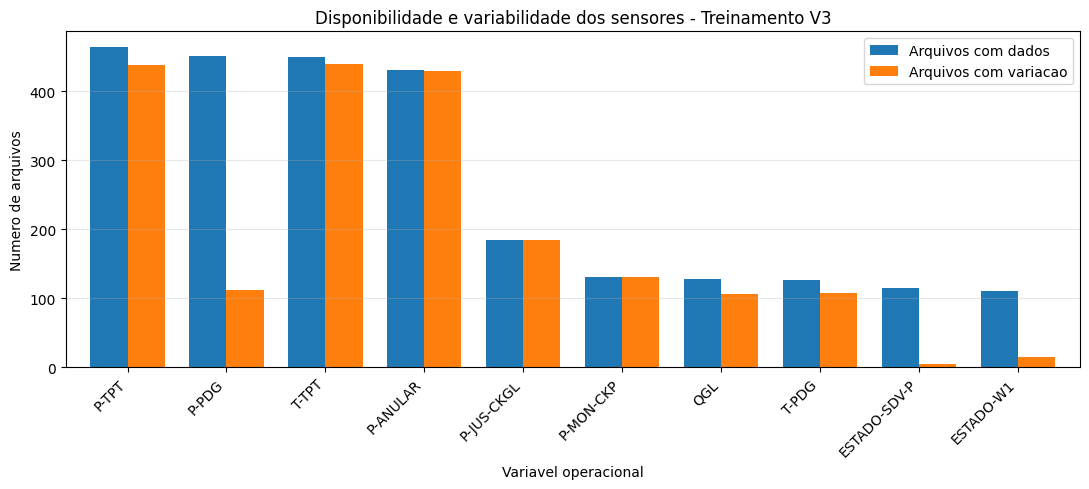


TAREFA 04 - ANALISE EXECUTADA


In [7]:

# SESSAO 05 - TAREFA 04
# Valores ausentes e sensores constantes

import pandas as pd
import matplotlib.pyplot as plt

qualidade = resumo_sensores.copy()

# Percentual de medicoes ausentes
qualidade["Medicoes_ausentes_%"] = (
    100 - qualidade["Medicoes_validas_%"]
).round(2)

# Percentual de arquivos constantes entre
# aqueles que possuem dados do sensor
qualidade["Constantes_entre_disponiveis_%"] = (
    100 * qualidade["Arquivos_constantes"]
    / qualidade["Arquivos_com_dados"].replace(0, float("nan"))
).round(2)

# Tabela de qualidade
colunas = [
    "Arquivos_com_dados",
    "Arquivos_variaveis",
    "Arquivos_constantes",
    "Medicoes_ausentes_%",
    "Constantes_entre_disponiveis_%"
]

print("DIAGNOSTICO DE QUALIDADE DOS SENSORES:")
display(qualidade[colunas])

# Grafico dos dez sensores mais disponiveis
top10 = qualidade.nlargest(
    10, "Disponibilidade_arquivos_%"
)

ax = top10[
    ["Arquivos_com_dados", "Arquivos_variaveis"]
].plot.bar(
    figsize=(11, 5),
    width=0.75
)

ax.set_title(
    "Disponibilidade e variabilidade dos sensores - Treinamento V3"
)
ax.set_xlabel("Variavel operacional")
ax.set_ylabel("Numero de arquivos")
ax.legend([
    "Arquivos com dados",
    "Arquivos com variacao"
])

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Salvar os resultados
qualidade.to_csv(
    "05_Qualidade_Sensores_V3.csv"
)

print("\nTAREFA 04 - ANALISE EXECUTADA")


In [8]:

# SESSAO 05 - TAREFA 05
# Estatisticas descritivas dos sensores candidatos

import io
import time
import requests
import pandas as pd
from tqdm.auto import tqdm

variaveis = ["P-TPT", "T-TPT", "P-ANULAR"]

estatisticas = []
amostras = []
falhas_estatisticas = []

with requests.Session() as sessao:
    for _, item in tqdm(
        dados_treino_v3.iterrows(),
        total=len(dados_treino_v3)
    ):
        arquivo = item["Arquivo"]
        categoria = int(item["Categoria"])

        url = (
            "https://raw.githubusercontent.com/petrobras/3W/"
            f"main/dataset/{categoria}/{arquivo}"
        )

        df = None

        for tentativa in range(3):
            try:
                resposta = sessao.get(url, timeout=60)
                resposta.raise_for_status()
                df = pd.read_parquet(io.BytesIO(resposta.content))
                break
            except Exception as erro:
                ultimo_erro = str(erro)
                if tentativa < 2:
                    time.sleep(2 ** (tentativa + 1))

        if df is None:
            falhas_estatisticas.append({
                "Arquivo": arquivo,
                "Erro": ultimo_erro
            })
            continue

        # Estatisticas por sensor e arquivo
        for sensor in variaveis:
            serie = df[sensor].dropna()

            if serie.empty:
                continue

            estatisticas.append({
                "Arquivo": arquivo,
                "Poco": item["Poco"],
                "Categoria": categoria,
                "Sensor": sensor,
                "N": len(serie),
                "Media": serie.mean(),
                "Desvio_padrao": serie.std(),
                "Minimo": serie.min(),
                "Mediana": serie.median(),
                "Maximo": serie.max()
            })

        # Guardar amostra para a Tarefa 06
        amostra = df[variaveis].sample(
            n=min(200, len(df)),
            random_state=42
        ).copy()

        amostra["Poco"] = item["Poco"]
        amostra["Categoria"] = categoria
        amostra["Arquivo"] = arquivo
        amostras.append(amostra)

# Organizar os resultados
estatisticas_arquivo = pd.DataFrame(estatisticas)

amostra_correlacao = pd.concat(
    amostras,
    ignore_index=True
) if amostras else pd.DataFrame()

# Resumo das estatisticas por sensor
resumo_estatistico = (
    estatisticas_arquivo.groupby("Sensor")
    .agg(
        Arquivos=("Arquivo", "nunique"),
        Mediana_das_medias=("Media", "median"),
        Mediana_dos_desvios=("Desvio_padrao", "median"),
        Minimo_observado=("Minimo", "min"),
        Maximo_observado=("Maximo", "max")
    )
    .round(3)
)

print("ARQUIVOS PROCESSADOS:",
      estatisticas_arquivo["Arquivo"].nunique())

print("FALHAS:", len(falhas_estatisticas))

print("\nRESUMO ESTATISTICO DOS SENSORES:")
display(resumo_estatistico)

print("\nMEDIANAS DAS MEDIAS POR CATEGORIA:")
display(
    estatisticas_arquivo.pivot_table(
        index="Categoria",
        columns="Sensor",
        values="Media",
        aggfunc="median"
    ).round(3)
)

if falhas_estatisticas:
    display(pd.DataFrame(falhas_estatisticas))

# Salvar resultados
estatisticas_arquivo.to_csv(
    "05_Estatisticas_Por_Arquivo_V3.csv",
    index=False
)

resumo_estatistico.to_csv(
    "05_Resumo_Estatistico_V3.csv"
)

amostra_correlacao.to_csv(
    "05_Amostra_Correlacao_V3.csv",
    index=False
)


  0%|          | 0/528 [00:00<?, ?it/s]

ARQUIVOS PROCESSADOS: 470
FALHAS: 0

RESUMO ESTATISTICO DOS SENSORES:


,Arquivos,Mediana_das_medias,Mediana_dos_desvios,Minimo_observado,Maximo_observado
Sensor,,,,,
P-ANULAR,431,1.219874e+07,85828.323,-7658084.00,4.349212e+07
P-TPT,464,9.194214e+06,82574.824,-8629852.00,8.170977e+07
T-TPT,450,1.172640e+02,0.172,-33.75,1.196060e+02



MEDIANAS DAS MEDIAS POR CATEGORIA:


Sensor,P-ANULAR,P-TPT,T-TPT
Categoria,,,
0,1.145785e+07,8.390393e+06,117.285
1,1.807143e+07,1.583581e+07,118.031
2,1.385069e+07,1.984164e+07,96.293
3,2.307598e+07,1.520600e+07,50.077
4,1.653800e+07,1.627259e+07,117.593
5,9.799845e+06,7.357511e+06,98.486
6,9.170728e+06,1.297576e+07,118.747
7,1.939350e+07,8.578494e+06,-33.750
8,8.474251e+06,1.061565e+07,9.333


CORRELACOES ENTRE SENSORES:


Arquivos  Mediana  Media
Sensor_1 Sensor_2                          
P-TPT    P-ANULAR       417    0.634  0.374
         T-TPT          435    0.170  0.134
T-TPT    P-ANULAR       421    0.523  0.386


MATRIZ DE CORRELACAO - MEDIANAS:


,P-TPT,T-TPT,P-ANULAR
P-TPT,1.000,0.170,0.634
T-TPT,0.170,1.000,0.523
P-ANULAR,0.634,0.523,1.000


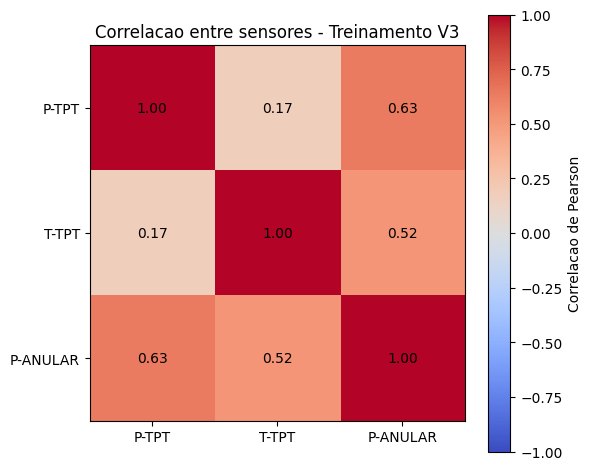


TAREFA 06 - ANALISE EXECUTADA


In [9]:

# SESSAO 05 - TAREFA 06
# Correlacao entre os sensores selecionados

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

variaveis = ["P-TPT", "T-TPT", "P-ANULAR"]

pares = [
    ("P-TPT", "T-TPT"),
    ("P-TPT", "P-ANULAR"),
    ("T-TPT", "P-ANULAR")
]

resultados_corr = []

# 1. Calcular a correlacao dentro de cada arquivo
for arquivo, grupo in amostra_correlacao.groupby("Arquivo"):

    for sensor1, sensor2 in pares:

        dados = grupo[[sensor1, sensor2]].dropna()

        # Exigir pelo menos 30 observacoes validas
        if len(dados) < 30:
            continue

        # Evitar correlacao de series constantes
        if (
            dados[sensor1].nunique() < 2
            or dados[sensor2].nunique() < 2
        ):
            continue

        r = dados[sensor1].corr(dados[sensor2])

        if pd.notna(r):
            resultados_corr.append({
                "Arquivo": arquivo,
                "Sensor_1": sensor1,
                "Sensor_2": sensor2,
                "Correlacao": r
            })

correlacoes = pd.DataFrame(resultados_corr)

if correlacoes.empty:
    raise ValueError("Nao houve pares validos para correlacao.")

# 2. Resumir as correlacoes por par de sensores
resumo_corr = correlacoes.groupby(
    ["Sensor_1", "Sensor_2"]
)["Correlacao"].agg(
    Arquivos="count",
    Mediana="median",
    Media="mean"
).round(3)

print("CORRELACOES ENTRE SENSORES:")
display(resumo_corr)

# 3. Construir matriz das medianas
matriz = pd.DataFrame(
    np.eye(3),
    index=variaveis,
    columns=variaveis
)

for (s1, s2), linha in resumo_corr.iterrows():
    valor = linha["Mediana"]
    matriz.loc[s1, s2] = valor
    matriz.loc[s2, s1] = valor

print("\nMATRIZ DE CORRELACAO - MEDIANAS:")
display(matriz.round(3))

# 4. Visualizar a matriz
fig, ax = plt.subplots(figsize=(6, 5))

imagem = ax.imshow(
    matriz,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(3), variaveis)
ax.set_yticks(range(3), variaveis)

for i in range(3):
    for j in range(3):
        valor = matriz.iloc[i, j]
        ax.text(
            j, i, f"{valor:.2f}",
            ha="center", va="center"
        )

ax.set_title(
    "Correlacao entre sensores - Treinamento V3"
)

fig.colorbar(imagem, ax=ax, label="Correlacao de Pearson")
plt.tight_layout()
plt.show()

# 5. Salvar resultados
correlacoes.to_csv(
    "05_Correlacoes_Por_Arquivo_V3.csv",
    index=False
)

resumo_corr.to_csv(
    "05_Resumo_Correlacoes_V3.csv"
)

print("\nTAREFA 06 - ANALISE EXECUTADA")
